# データサイエンス実践A 第８講：複合グラフと注釈
### 新潟大学 創生学部（2026年度）
**講義日：2026年10月30日（金）**

1. 最初に、第７講でできなかった**辞書**の基礎を学ぶ（Y）。
1. 次に、棒グラフと折れ線グラフを重ね、左右に y 軸を持つ**複合グラフ**を描く（ひな形を写して使う）。
1. そのあと、大きな数を「万件」などに直す**単位の変え方**と、データはそのままで目盛りだけを変える**対数目盛**を学ぶ。
1. 最後に、グラフに文字や矢印を書く**注釈**（`plt.text`・`plt.annotate`）を学ぶ。
1. CES-Alpha の演習「第８講」の `dict_第８講1`、`twinx_第８講1`、`twinx_第８講2`、`unit_第８講1`、`log_第８講1`、`log_第８講2`、`text_第８講1`、`annotate_第８講1` を解く。辞書の演習は、CES-Alpha の演習「第７講」の `dict_第７講1`〜`dict_第７講3`。
1. セルは**上から順番に**実行すること（`Shift + Enter` で実行して次のセルへ進む）。

## 目次
**[前回の振り返り](#前回の振り返り)**

**[Y. 辞書の基礎（第７講の続き）](#Y.-辞書の基礎（第７講の続き）)**
- [Y-1 辞書の基礎](#Y-1-辞書の基礎)
- [Y-2 オプションの辞書](#Y-2-オプションの辞書)

**[Z. 複合グラフ・両 y 軸](#Z.-複合グラフ・両-y-軸)**
- [Z-0 今日の完成形](#Z-0-今日の完成形)
- [Z-1 2つのグラフを重ねる](#Z-1-2つのグラフを重ねる)
- [Z-2 右にもう1本 y 軸を作る（ひな形）](#Z-2-右にもう1本-y-軸を作る（ひな形）)
- [Z-3 単位を変える](#Z-3-単位を変える)
- [Z-4 対数目盛（データはそのまま）](#Z-4-対数目盛（データはそのまま）)

**[V. 注釈：グラフに文字を書く](#V.-注釈：グラフに文字を書く)**
- [V-1 plt.text の基本](#V-1-plt.text-の基本)
- [V-2 文字の大きさ・色・位置](#V-2-文字の大きさ・色・位置)
- [V-3 矢印付きの注釈](#V-3-矢印付きの注釈)

**[まとめ](#まとめ)**

---
# 前回の振り返り

- 新しい notebook はいつもの場所（ホームフォルダ）に作る
- 前回は値を数える `df['列名'].value_counts()` を学んだ。数えた結果は「名前と件数の組」。予定していた**辞書**は時間が足りなかったので、今日の最初（Y）に学ぶ
- 棒グラフの補足：横軸の名前を書き換える `plt.xticks`、並べ替える `.reindex([...])`、棒の上に値を書く `plt.bar_label`、積み上げる `bottom=`
- 箱ひげ図は `plt.boxplot([データ1, データ2])`。箱の中の線は**中央値**

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import japanize_matplotlib

df = pd.read_excel('dsa2026data.xlsx', sheet_name='降水量')
df

,月,降水量,気温
0,1,180.0,4.3
1,2,114.5,4.8
2,3,168.0,6.0
3,4,54.0,13.7
4,5,128.0,17.1
5,6,57.0,22.2
6,7,376.5,26.2
7,8,42.0,28.0
8,9,292.0,25.0
9,10,144.5,18.7


- 表が出れば準備完了。`FileNotFoundError` が出たら、`dsa2026data.xlsx` を notebook と同じ場所に置く（第５講 L-1）

---
# Y. 辞書の基礎（第７講の続き）

第７講で予定していた辞書を、ここで学ぶ。今日の注釈（V-3）の `arrowprops={'arrowstyle': '->'}` も辞書を使っている。

## Y-1 辞書の基礎

- **辞書**は、「**キー**（名前）」と「**値**」を `:` でつないだ組を、`{ }` の中に並べたもの
- リストは番号（`[0]`, `[1]`, …）で取り出すが、辞書は**キー**で取り出す
- 例：在籍番号（キー）と名前（値）の組（架空のデータ）

In [2]:
students = {'S001': '新潟 太郎', 'S002': '古町 花子', 'S003': '万代 次郎'}

print(students['S002'])
print(len(students))

古町 花子
3


- `辞書['キー']` で、そのキーの値を取り出す
- `len(辞書)` で、組の個数が分かる
- `辞書['キー'] = 値` で、組を**追加**する。すでにあるキーなら、値が**上書き**される

In [3]:
students['S004'] = '白山 さくら'
students['S001'] = '新潟 一郎'

print(students)

{'S001': '新潟 一郎', 'S002': '古町 花子', 'S003': '万代 次郎', 'S004': '白山 さくら'}


- 同じキーは2つ持てない。`'S001'` は追加ではなく上書きになった
- ないキーを指定すると `KeyError: 'S005'` というエラーになる（エラー文の最後に、見つからなかったキーが出る）
- 第７講 Q-1 の `value_counts()` の結果も「名前と件数の組」なので、辞書と同じように `count['No']` で取り出せる

▶ **演習**：`dict_第７講1`（在籍番号と名前の辞書）、`dict_第７講2`（値を直して表示する）、`dict_第８講1`（値段の辞書で計算・追加・上書き）

## Y-2 オプションの辞書

- 第６講の円グラフの `wedgeprops={'edgecolor': 'w'}` は、「扇の部品（wedge）の設定（props）」を辞書で渡していた。キーが**設定の名前**、値が**設定値**
- 設定が2つ以上あるときは、`,` で区切って並べる

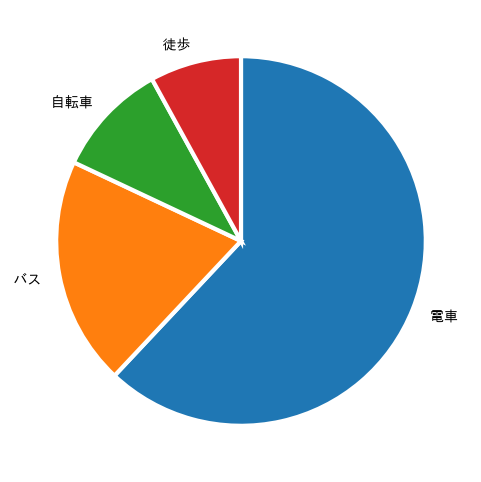

In [4]:
plt.figure(figsize=(6, 6))
plt.pie([62, 20, 10, 8], labels=['電車', 'バス', '自転車', '徒歩'], startangle=90, counterclock=False,
        wedgeprops={'edgecolor': 'w', 'linewidth': 3})
plt.show()

- `'linewidth': 3` で境目の線を太くした
- 第７講の箱ひげ図（S-4）の `boxprops={'facecolor': 'lightblue'}` も同じ形（箱の部品の設定）
- 今日の V-3 の `arrowprops={'arrowstyle': '->'}` も同じ形（矢印の部品の設定）

▶ **演習**：`dict_第７講3`（円グラフの境目を辞書で指定する）

---
# Z. 複合グラフ・両 y 軸

## Z-0 今日の完成形

降水量（棒グラフ）と気温（折れ線グラフ）を1枚に重ね、左に降水量、右に気温の y 軸を付けたもの。大雨の7月には矢印で、最高気温の8月には文字で説明を書いている。

1. **全部コピーして**自分の notebook のセルに貼り付け、実行する
1. まずは**数値や文字を変えて**、グラフのどこが変わるかを確かめる
1. そのあと部品（[1]〜[5]）の働きを1つずつ学ぶ（Z-1〜Z-2、V-1〜V-3）

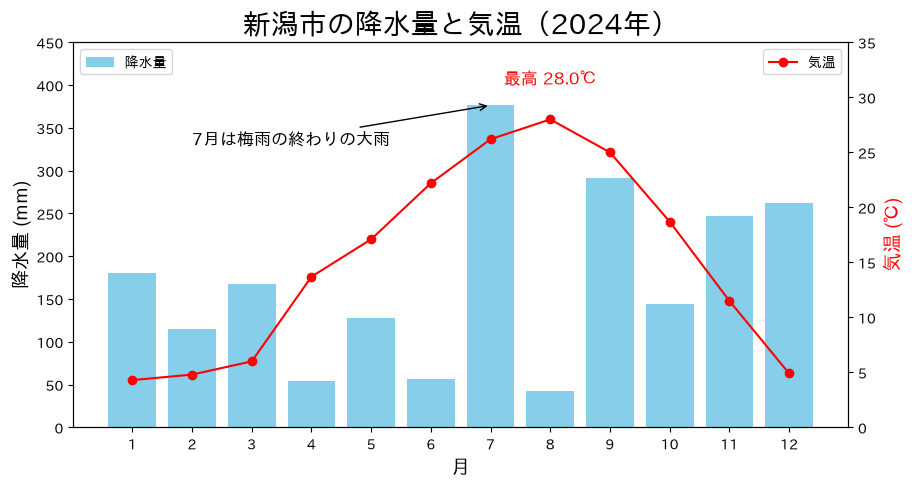

In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import japanize_matplotlib

df = pd.read_excel('dsa2026data.xlsx', sheet_name='降水量')

plt.figure(figsize=(10, 5))  # [0] グラフの大きさ

plt.bar(df['月'], df['降水量'], color='skyblue', label='降水量')  # [1] 左の y 軸に棒グラフ
plt.ylabel('降水量 (mm)', fontsize=14)
plt.ylim(0, 450)
plt.annotate('7月は梅雨の終わりの大雨', xy=(7, 376.5), xytext=(2, 330), fontsize=12,
             arrowprops={'arrowstyle': '->'})  # [4] 矢印付きの注釈
plt.xlabel('月', fontsize=14)
plt.xticks(range(1, 13))
plt.title('新潟市の降水量と気温（2024年）', fontsize=20)
plt.legend(loc='upper left')

plt.twinx()  # [2] 右にもう1本 y 軸を作る
plt.plot(df['月'], df['気温'], color='r', marker='o', label='気温')  # [3] 右の y 軸に折れ線グラフ
plt.ylabel('気温 (℃)', color='r', fontsize=14)
plt.ylim(0, 35)
plt.text(8, 31, '最高 28.0℃', color='r', ha='center', va='bottom', fontsize=12)  # [5] 文字を書く
plt.legend(loc='upper right')

plt.show()

### 変えてみよう（1か所変えたら、もう一度実行する）

- `plt.twinx()` の行を消すと、気温の線がどうなるか（Z-1）
- `xytext=(2, 330)` → `xytext=(9, 420)`（説明の文字が動く。矢印の先は動かない）
- `plt.text(8, 31, …)` の `31` → `33`
- `color='r'` → `color='orange'`

| 番号 | 部品 | 書き方 | 学ぶところ |
|---|---|---|---|
| [0] | グラフの大きさ（書かなくてもよい） | `plt.figure(figsize=(10, 5))` | |
| [1] | 左の y 軸に棒グラフ | `plt.bar(…)`、`plt.ylabel('降水量 (mm)')` | Z-2 |
| [2] | 右にもう1本 y 軸を作る | `plt.twinx()` | Z-2 |
| [3] | 右の y 軸に折れ線グラフ | `plt.plot(…)`、`plt.ylabel('気温 (℃)', color='r')` | Z-2 |
| [4] | 矢印付きの注釈 | `plt.annotate('文字', xy=(…), xytext=(…), arrowprops={…})` | V-3 |
| [5] | 文字を書く | `plt.text(横の位置, 縦の位置, '文字')` | V-1・V-2 |

In [6]:
# 上のコードを貼り付けて、値を変えてみよう

## Z-1 2つのグラフを重ねる

- 降水量（棒グラフ）と気温（折れ線グラフ）を1枚に描きたい。そのまま重ねると、単位（mm と ℃）も大きさも違うので、気温の線が下につぶれる

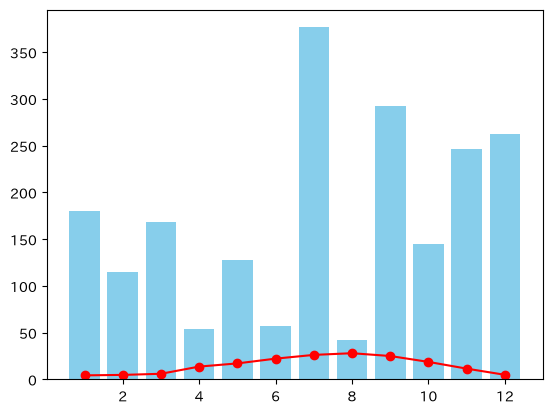

In [7]:
plt.bar(df['月'], df['降水量'], color='skyblue')
plt.plot(df['月'], df['気温'], color='r', marker='o')
plt.show()

## Z-2 右にもう1本 y 軸を作る（ひな形）

- `plt.twinx()` で、**右側にもう1本 y 軸**を作る。`plt.twinx()` の**前**に書いたものは左の y 軸、**後**に書いたものは右の y 軸に付く
- **下のセルはひな形**。列名・ラベル・色を変えれば、そのまま使える（第２回課題でも使う）

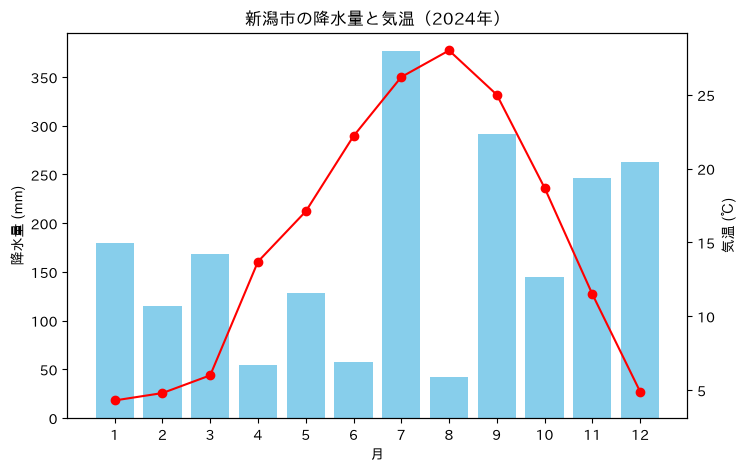

In [8]:
plt.figure(figsize=(8, 5))

# 左の y 軸（棒グラフ）と、両方に共通する設定
plt.bar(df['月'], df['降水量'], color='skyblue', label='降水量')
plt.ylabel('降水量 (mm)')
plt.xlabel('月')
plt.title('新潟市の降水量と気温（2024年）')
plt.xticks(range(1, 13))

# 右の y 軸を追加（折れ線グラフ）
plt.twinx()
plt.plot(df['月'], df['気温'], color='r', marker='o', label='気温')
plt.ylabel('気温 (℃)')

plt.show()

- 横軸の設定（`xlabel`・`xticks`）と `title` は、`plt.twinx()` の**前**に書く
- どちらの軸がどのグラフか分かるように、**y 軸の名前に単位**を書く。色をそろえる（右の軸の名前を赤にする：`plt.ylabel('気温 (℃)', color='r')`）のもよい
- 凡例は、左右で別々になる。`plt.legend(loc='upper left')` と `plt.legend(loc='upper right')` のように、位置を分けて書く（Z-0）

▶ **演習**：`twinx_第８講1`

## Z-3 単位を変える

- `accident` シートは、全国の交通事故件数・死者数・負傷者数など（2000〜2025年）

In [9]:
df_acc = pd.read_excel('dsa2026data.xlsx', sheet_name='accident')
df_acc.head()

,年,交通事故件数,死者数,負傷者数,重傷者数
0,2000,931950,9073,1155707,80105
1,2001,947253,8757,1181039,79677
2,2002,936950,8396,1168029,78297
3,2003,948281,7768,1181681,75112
4,2004,952720,7436,1183617,72817


- 負傷者数を、そのまま折れ線グラフにしてみる

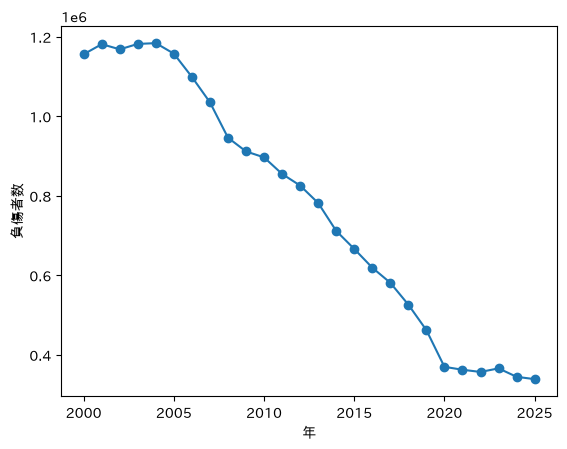

In [10]:
plt.plot(df_acc['年'], df_acc['負傷者数'], marker='o')
plt.xlabel('年')
plt.ylabel('負傷者数')
plt.show()

- 縦軸の左上に `1e6` と出る。これは「目盛りの数 × 10 の 6 乗（100万）」という意味。目盛りの `1.0` は 1.0 × 100万 ＝ 100万人
- このままでは読みにくい。データを割って**単位を変える**と読みやすくなる。`df_acc['負傷者数'] / 10000` で「万人」になる
- 単位を変えたら、**軸の名前にも単位**を書く

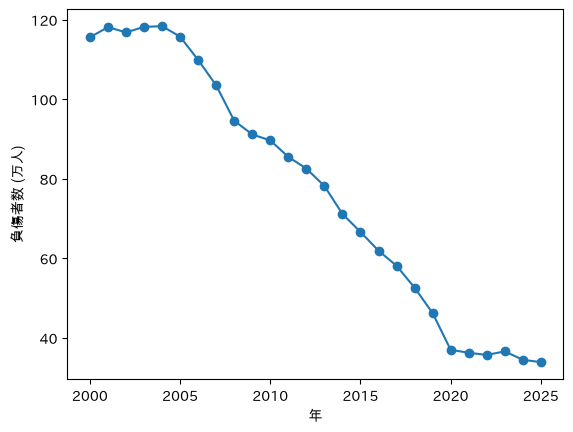

In [11]:
plt.plot(df_acc['年'], df_acc['負傷者数'] / 10000, marker='o')
plt.xlabel('年')
plt.ylabel('負傷者数 (万人)')
plt.show()

- 目盛りが 40〜120 になり、「2004年は約118万人、2025年は約34万人」と読める
- 100万より小さい数でも、交通事故件数（最大 約95万件）のように桁が多いと読みにくい。同じように `/ 10000` で「万件」にするとよい
- ほかの例：円 → 千円（`/ 1000`）、人 → 千人（`/ 1000`）、g → kg（`/ 1000`）

### 使ってみよう
- 交通事故件数（万件、棒グラフ）と死者数（人、折れ線グラフ）の複合グラフを、Z-2 のひな形を直して描いてみよう

▶ **演習**：`unit_第８講1`、`twinx_第８講2`（複合グラフと単位）

In [12]:
# ここで試してみよう

## Z-4 対数目盛（データはそのまま）

- `worldbank` シートは、人口の多い30か国の一人あたり GDP（ドル）と平均寿命（2024年）
- 一人あたり GDP は、約700ドルから約86,000ドルまで、**100倍以上**の差がある。そのまま散布図にしてみる

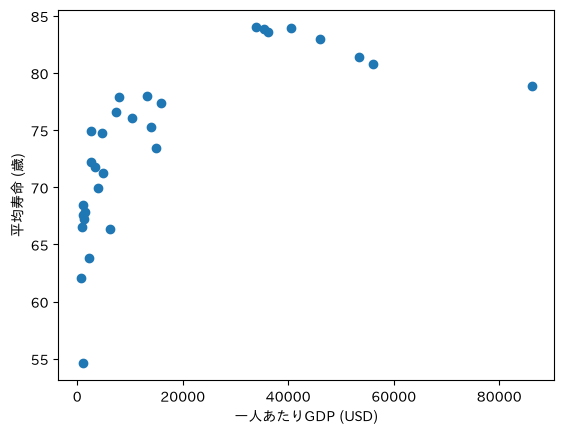

In [13]:
df_wb = pd.read_excel('dsa2026data.xlsx', sheet_name='worldbank')

plt.scatter(df_wb['一人あたりGDP'], df_wb['出生時平均寿命'])
plt.xlabel('一人あたりGDP (USD)')
plt.ylabel('平均寿命 (歳)')
plt.show()

- 多くの点が左に集まり、GDP の低い国どうしの違いが見えない

### よくある方法：データの対数を取る

- `np.log10(…)` で、データを「10 の何乗か」に変えると、点は広がる

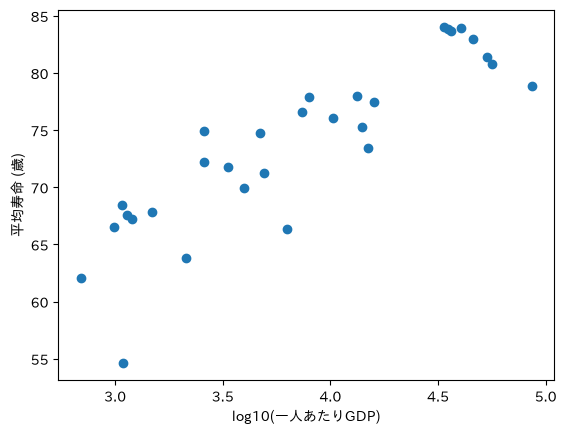

In [14]:
plt.scatter(np.log10(df_wb['一人あたりGDP']), df_wb['出生時平均寿命'])
plt.xlabel('log10(一人あたりGDP)')
plt.ylabel('平均寿命 (歳)')
plt.show()

- 点は広がったが、横軸の目盛りが 3.0、3.5、4.0 … になる。3 は 1000 ドル、4 は 1万ドルのことだが、目盛りを見てもすぐには何ドルか分からない
- **データそのものを変えてしまった**ので、表の数とグラフの数が食い違う

### 対数目盛：表示だけを変える

- `plt.xscale('log')` を1行足すと、**データはそのまま**で、横軸の目盛りだけが対数（1目盛りごとに10倍）になる

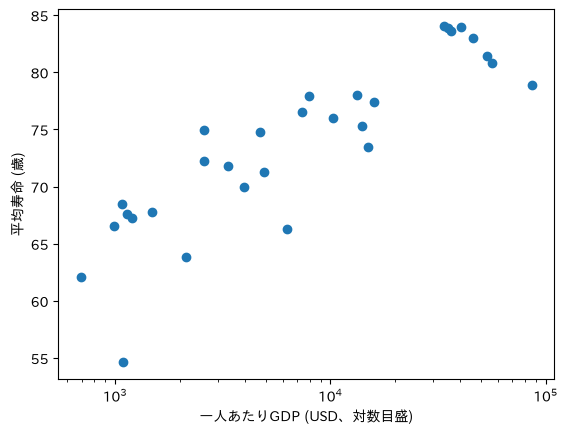

In [15]:
plt.scatter(df_wb['一人あたりGDP'], df_wb['出生時平均寿命'])
plt.xscale('log')
plt.xlabel('一人あたりGDP (USD、対数目盛)')
plt.ylabel('平均寿命 (歳)')
plt.show()

- 点の広がり方は `np.log10` のときと同じだが、目盛りは $10^3$（1000ドル）、$10^4$（1万ドル）、$10^5$（10万ドル）と**元の単位のまま**読める。間の小さい目盛りは 2000、3000、…、9000 ドル
- 縦軸を対数目盛にするときは `plt.yscale('log')`
- 対数目盛にしたら、軸の名前に「対数目盛」と書く（等間隔だと思われないように）
- 0 やマイナスの値は、対数目盛には描けない

| | 単位を変える（Z-3） | 対数目盛（Z-4） |
|---|---|---|
| 書き方 | `df['列名'] / 10000` | `plt.xscale('log')`・`plt.yscale('log')` |
| データ | 割った値に変わる | **そのまま** |
| 目盛り | 等間隔（10、20、30 …） | 10倍ごとに同じ間隔（10、100、1000 …） |
| 向いているとき | 桁が多くて読みにくい | 値の差が何十倍・何百倍もある |

▶ **演習**：`log_第８講1`、`log_第８講2`（散布図の対数目盛と国名）

In [16]:
# ここで試してみよう

---
# V. 注釈：グラフに文字を書く

グラフの伝えたいところに文字や矢印を書くと、見る人に「どこを見ればよいか」が伝わる。

## V-1 plt.text の基本

第４講 H-10 で、散布図の点に1つだけ名前を付けた。ここでくわしく学ぶ。

- `plt.text(x, y, '文字')` で、**グラフの目盛りで** (x, y) の位置に文字を書く
- 文字の代わりに数（変数）を渡してもよい

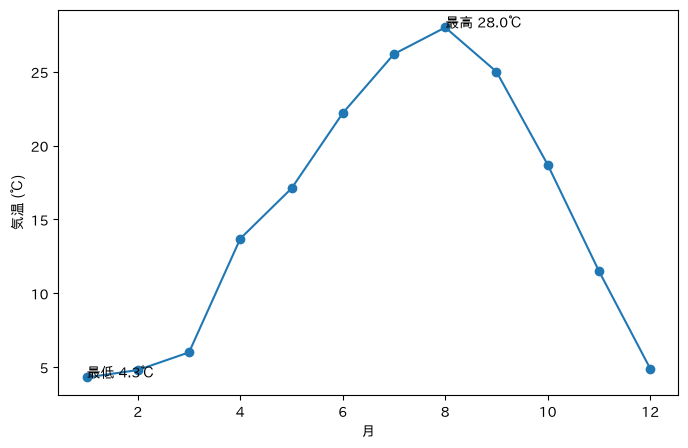

In [17]:
plt.figure(figsize=(8, 5))
plt.plot(df['月'], df['気温'], marker='o')
plt.text(8, 28, '最高 28.0℃')
plt.text(1, 4.3, '最低 4.3℃')
plt.xlabel('月')
plt.ylabel('気温 (℃)')
plt.show()

- 点と文字が重なって読みにくい。位置を少しずらす（V-2）

## V-2 文字の大きさ・色・位置

| 書き方 | 意味 |
|---|---|
| `fontsize=12` | 文字の大きさ |
| `color='r'` | 文字の色 |
| `ha='center'` | 横の位置合わせ：`'left'`（指定した点から右へ書く。何も書かないとこれ）、`'center'`（点が文字の中央）、`'right'` |
| `va='bottom'` | 縦の位置合わせ：`'bottom'`（点の上に書く）、`'center'`、`'top'`（点の下に書く） |

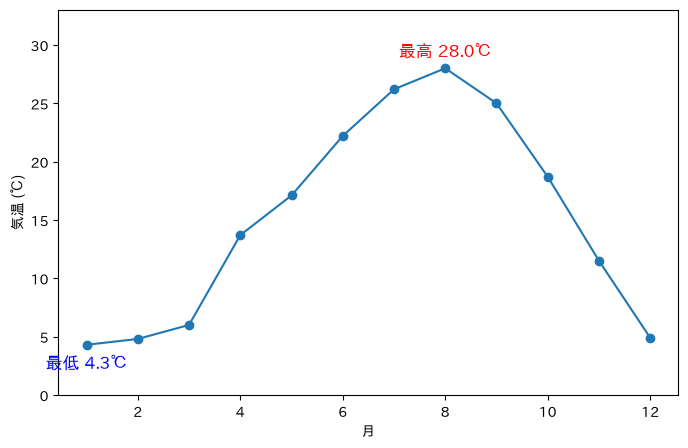

In [18]:
plt.figure(figsize=(8, 5))
plt.plot(df['月'], df['気温'], marker='o')
plt.text(8, 28.8, '最高 28.0℃', ha='center', va='bottom', color='r', fontsize=12)
plt.text(1, 3.5, '最低 4.3℃', ha='center', va='top', color='b', fontsize=12)
plt.ylim(0, 33)
plt.xlabel('月')
plt.ylabel('気温 (℃)')
plt.show()

### 複数行の注釈

- 第５講 K-3 で紹介した `\n`（改行）を使うと、注釈を2行以上にできる

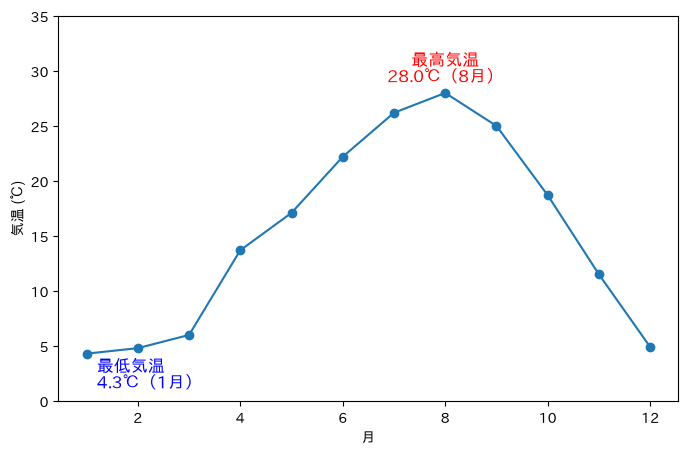

In [19]:
plt.figure(figsize=(8, 5))
plt.plot(df['月'], df['気温'], marker='o')
plt.text(8, 28.8, '最高気温\n28.0℃（8月）', ha='center', va='bottom', color='r', fontsize=12)
plt.text(1.2, 4, '最低気温\n4.3℃（1月）', ha='left', va='top', color='b', fontsize=12)
plt.ylim(0, 35)
plt.xlabel('月')
plt.ylabel('気温 (℃)')
plt.show()

- `'…\n…'` で2行になる。`ha='center'` で各行が中央にそろう（最低気温のように `ha='left'` なら左そろえ）
- `va='bottom'` は文字のかたまり全体の下端を点の位置に合わせる。行が増えると上に伸びるので、`plt.ylim` で上を空ける
- 行の間隔は `linespacing=1.5` などで変えられる
- 複合グラフでは、`plt.twinx()` の**後**に書いた `plt.text` は、**右の y 軸**の目盛りで位置を決める（Z-0 の [5]）
- 棒の上に値を書くだけなら、第７講 R-3 の `plt.bar_label` が簡単

▶ **演習**：`text_第８講1`

## V-3 矢印付きの注釈

| | `plt.text` | `plt.annotate` |
|---|---|---|
| 指定する位置 | 1つ：文字を置く場所 | 2つ：指したい点 `xy` と、文字を置く場所 `xytext` |
| 矢印 | なし | `arrowprops={…}` で付く |
| 向いているとき | 点のすぐそばに書けるとき（V-1・V-2 の最高・最低気温） | 点のまわりが混んでいて、空いているところに文字を置きたいとき |

- 7月の大雨の説明を、空いている左上（3, 350）に `plt.text` で書いてみる

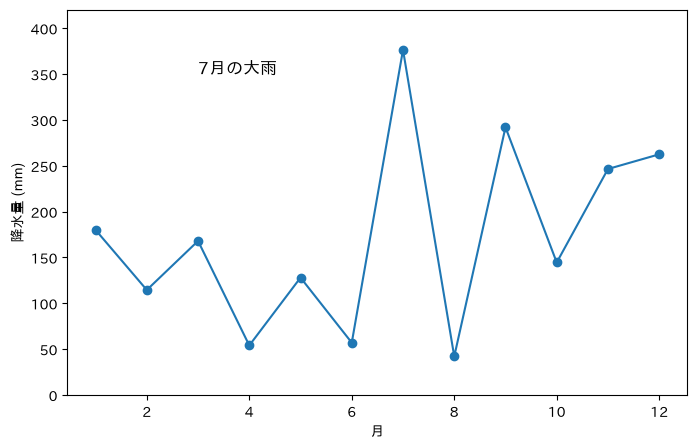

In [20]:
plt.figure(figsize=(8, 5))
plt.plot(df['月'], df['降水量'], marker='o')
plt.text(3, 350, '7月の大雨', fontsize=12)
plt.ylim(0, 420)
plt.xlabel('月')
plt.ylabel('降水量 (mm)')
plt.show()

- 文字は読めるが、**どの点の説明か分からない**。`plt.text` は文字の位置しか指定できない
- `plt.annotate` なら、同じ場所に文字を置いたまま、矢印で7月の点を指せる
- `plt.annotate('文字', xy=(指したい点), xytext=(文字の位置), arrowprops={'arrowstyle': '->'})` で、矢印付きの注釈を書ける
- `xy` が**矢印の先**、`xytext` が**文字を置く場所**。どちらもグラフの目盛りで書く
- `arrowprops` の `{ }` は Y-2 の**辞書**。`'color': 'r'` を足すと矢印が赤になる

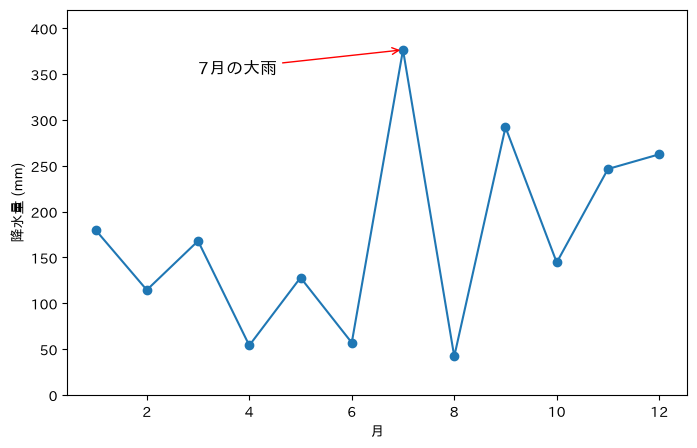

In [21]:
plt.figure(figsize=(8, 5))
plt.plot(df['月'], df['降水量'], marker='o')
plt.annotate('7月の大雨', xy=(7, 376.5), xytext=(3, 350), fontsize=12,
             arrowprops={'arrowstyle': '->', 'color': 'r'})
plt.ylim(0, 420)
plt.xlabel('月')
plt.ylabel('降水量 (mm)')
plt.show()

### 変えてみよう
- `'arrowstyle': '->'` → `'-|>'`（矢印の形が変わる）
- `xytext=(3, 350)` → `xytext=(10, 400)`

### 使ってみよう
- Z-3 の負傷者数（万人）の折れ線グラフに、いちばん多い 2004 年（約118.4万人）を指す矢印と説明を書いてみよう

▶ **演習**：`annotate_第８講1`

In [22]:
# ここで試してみよう

---
# まとめ

| やりたいこと | 書き方 |
|---|---|
| **以下は複合グラフ** | |
| 右に y 軸を作る | `plt.twinx()`（前に書いたものは左、後に書いたものは右） |
| 凡例を左右に分ける | `plt.legend(loc='upper left')`、`plt.legend(loc='upper right')` |
| 軸の名前の色 | `plt.ylabel('気温 (℃)', color='r')` |
| **以下は単位・目盛り** | |
| `1e6` の意味 | 目盛りの数 × 100万 |
| 単位を変える | `df['列名'] / 10000`（万）、`df['列名'] / 1000`（千）。軸の名前にも単位を書く |
| 対数目盛（データはそのまま） | `plt.xscale('log')`（横軸）、`plt.yscale('log')`（縦軸）。`np.log10` でデータを変えない |
| **以下は注釈** | |
| 文字を書く | `plt.text(x, y, '文字')` |
| 位置・大きさ・色 | `ha='center'`、`va='bottom'`、`fontsize=12`、`color='r'` |
| 複数行の注釈 | `plt.text(x, y, '1行目\n2行目')` |
| 矢印付きの注釈 | `plt.annotate('文字', xy=(矢印の先), xytext=(文字の位置), arrowprops={'arrowstyle': '->'})` |

次回（第９講）は**伝わるグラフ・遊び心のあるグラフ**（グラフを並べる、誤解を招くグラフ、遊び心のあるグラフ）。